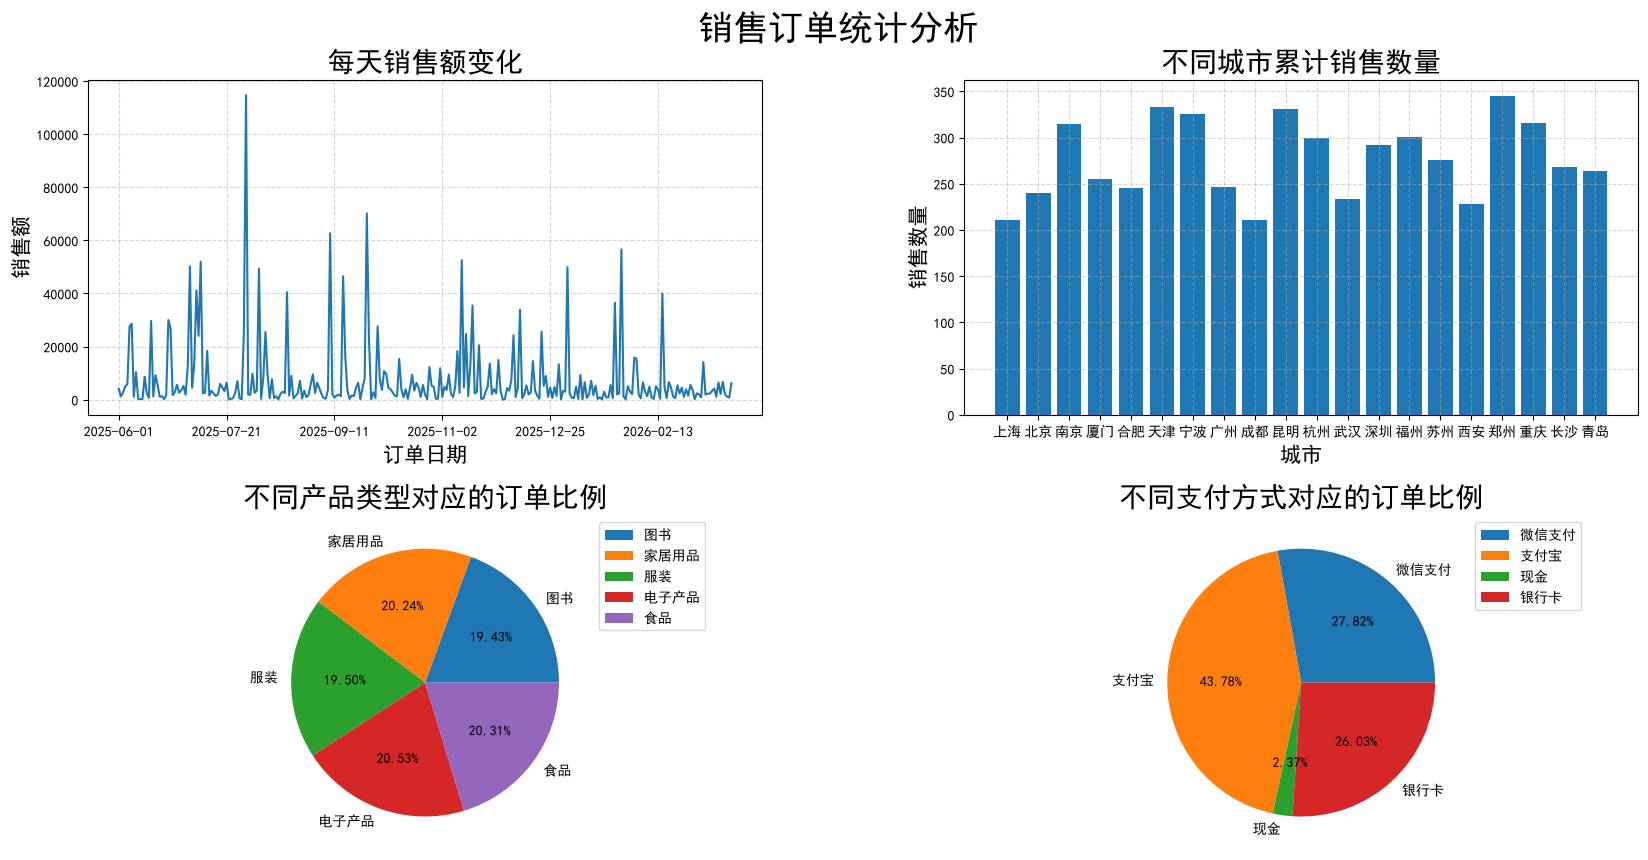

In [54]:
'''
需求 1：统计每天销售额的变化。（折线图）
需求 2：统计对比不同城市的累计销售数量。（柱状图）
需求 3：统计不同产品类型对应的订单比例。（饼状图）
需求 4：统计不同支付方式对应的订单比例。（饼状图）
'''
import pandas as pd
import matplotlib.pyplot as plt
import os

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['SimHei']

# 读取数据
data = pd.read_csv('csv_data/sales.csv',usecols=['产品类别','销售数量','单价','客户所在城市','订单日期','支付方式'])
data['销售额'] = data['销售数量'] * data['单价']

# 处理异常
# 删掉缺失值
data.dropna()

# 将单价为负的取绝对值
data['单价'] = data['单价'].abs()

# 统一日期格式
data['订单日期'] =data['订单日期'].str.replace('/','-')

# 数据可视化
fig , axes = plt.subplots(2,2,figsize=(20,10),dpi=100)
fig.suptitle('销售订单统计分析',fontsize=25,y=0.95)
fig.subplots_adjust(wspace=0.3, hspace=0.3)


# 获取子图
ax1:plt.Axes = axes[0,0]
ax2:plt.Axes = axes[0,1]
ax3:plt.Axes = axes[1,0]
ax4:plt.Axes = axes[1,1]

# 需求 1：统计每天销售额的变化。（折线图）
daily_sales = data.groupby('订单日期')['销售额'].sum()

x = daily_sales.index.tolist()
y = daily_sales.values.tolist()

ax1.plot(x,y)
ax1.set_title('每天销售额变化',fontsize=20)
ax1.set_xlabel('订单日期',fontsize=15)
ax1.set_ylabel('销售额',fontsize=15)
ax1.set_xticks(x[::50])
ax1.grid(linestyle = '--',alpha=0.5)


# 需求 2：统计对比不同城市的累计销售数量。（柱状图）
city_sales = data.groupby('客户所在城市')['销售数量'].sum()

x = city_sales.index.tolist()
y = city_sales.values.tolist()

ax2.bar(x,y,width=0.8)
ax2.set_title('不同城市累计销售数量',fontsize=20)
ax2.set_xlabel('城市',fontsize=15)
ax2.set_ylabel('销售数量',fontsize=15)
ax2.grid(linestyle = '--',alpha=0.5)

# 需求 3：统计不同产品类型对应的订单比例。（饼状图）
product_type_sales = data.groupby('产品类别')['销售数量'].sum()

x = product_type_sales.index.tolist()
y = product_type_sales.values.tolist()

ax3.pie(y,labels=x,autopct='%1.2f%%')
ax3.set_title('不同产品类型对应的订单比例',fontsize=20)
ax3.legend(loc='upper left',bbox_to_anchor=(1,1))

# 需求 4：统计不同支付方式对应的订单比例。（饼状图）
payment_method_sales = data.groupby('支付方式')['销售数量'].sum()

x = payment_method_sales.index.tolist()
y = payment_method_sales.values.tolist()

ax4.pie(y,labels=x,autopct='%1.2f%%')
ax4.set_title('不同支付方式对应的订单比例',fontsize=20)
ax4.legend(loc='upper left',bbox_to_anchor=(1,1))

# 保存图片
os.makedirs('data',exist_ok=True)
plt.savefig('data/销售订单统计分析.png',dpi=100)

# 显示图片
plt.show()